# nnae : auto-encodeur à plus proche voisin (pompe, DCASE 2020 Task 2)

Un auto-encodeur entraîné sur des sons normaux reconstruit mal ce qu'il n'a jamais entendu : son erreur de
reconstruction sert de score d'anomalie. Mais il généralise parfois trop et reconstruit aussi les anomalies.

**Idée du nnae** : le décodeur ne reçoit pas seulement le code `z` du son, mais un mélange avec le code du
**plus proche son normal** de la même machine :

$$z_{mix} = \alpha \, z + (1 - \alpha) \, z_{voisin}, \qquad \alpha = 0.1$$

Un son normal a un voisin proche, donc il est bien reconstruit ; un son anormal n'en a pas : sa reconstruction est
tirée vers du normal et son erreur augmente.

| Modèle (pompe) | AUC | pAUC |
|---|---|---|
| Baseline du papier (AE, 100 epochs) | 72.89 | 59.99 |
| nnae, α = 0.5 / 0.25 / **0.1** / 0 (10 epochs) | 72.0 / 75.0 / **76.0** / 72.0 | 60.2 / 64.3 / **64.8** / 61.4 |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Audio, display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_auc_score
from torch import nn
from torch.utils.data import BatchSampler, DataLoader, Dataset, RandomSampler

ROOT = Path.cwd() if (Path.cwd() / "train.py").exists() else Path.cwd().parent
DATA = ROOT / "data" / "pump"                       # log-mel .npy créés par prepare_data.py
WAV = ROOT / "data" / "dcase2020" / "pump" / "test"  # sons d'origine, pour l'écoute
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

ALPHA, MEMORY_SIZE, EPOCHS, BATCH, LR = 0.1, 128, 10, 512, 1e-3
torch.manual_seed(0)

## 1. Données

Pompe du DCASE 2020 Task 2 : 4 machines (`id_00` à `id_06`), sons de 10 s à 16 kHz. L'entraînement ne contient
que des sons **normaux** ; le test mélange sons normaux et anomalies (fuite, contamination, colmatage…).
Chaque son est déjà converti en log-mel : 128 bandes de fréquence × 313 trames de 32 ms.

In [2]:
def machine_id(path):
    return int(path.stem.split("id_")[1][:2])  # normal_id_04_00000012 -> 4


folders = ["train/normal", "val/normal", "test/normal", "test/anomalie"]
files = {f: sorted((DATA / f).glob("*.npy")) for f in folders}
pd.DataFrame({f: pd.Series([f"id_{machine_id(p):02d}" for p in files[f]]).value_counts() for f in folders})

,train/normal,val/normal,test/normal,test/anomalie
id_00,824,82,100,143
id_02,820,85,100,111
id_04,542,60,100,100
id_06,828,108,100,102


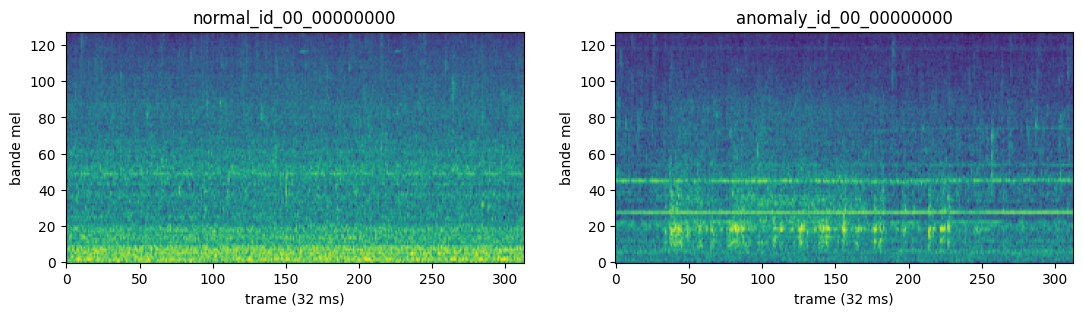

In [3]:
examples = [files["test/normal"][0], files["test/anomalie"][0]]
fig, axes = plt.subplots(1, 2, figsize=(13, 3))
for ax, path in zip(axes, examples):
    ax.imshow(np.load(path), origin="lower", aspect="auto")
    ax.set(title=path.stem, xlabel="trame (32 ms)", ylabel="bande mel")
plt.show()
for path in examples:
    display(Audio(str(WAV / f"{path.stem}.wav")))

## 2. Dataset

Comme dans la baseline, l'entrée du modèle est un vecteur de **5 trames consécutives** (5 × 128 = 640 valeurs) :
un son de 313 trames donne 309 vecteurs. Le dataset garde aussi, pour chaque vecteur, l'ID de la machine et le
numéro du son (pour chercher le voisin dans un *autre* son).

In [4]:
def to_vectors(mel, n_frames=5):
    """Log-mel (128, T) -> (T - 4, 640) : 5 trames consécutives concaténées."""
    frames = torch.as_tensor(mel).T
    return frames.unfold(0, n_frames, 1).transpose(1, 2).reshape(-1, 128 * n_frames)


class PumpVectors(Dataset):
    """Vecteurs de tous les sons d'un dossier, avec l'ID de machine et le numéro du son de chaque vecteur."""

    def __init__(self, folder):
        self.files = sorted((DATA / folder).glob("*.npy"))
        x, ids, sounds = [], [], []
        for i, path in enumerate(self.files):
            v = to_vectors(np.load(path))
            x.append(v)
            ids.append(torch.full((len(v),), machine_id(path)))
            sounds.append(torch.full((len(v),), i))
        self.x, self.ids, self.sounds = torch.cat(x), torch.cat(ids), torch.cat(sounds)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, i):  # i est une liste d'indices : tout un batch est extrait d'un coup
        return self.x[i], self.ids[i], self.sounds[i]


def loader(ds, shuffle=False, batch=BATCH):
    order = RandomSampler(ds) if shuffle else range(len(ds))
    return DataLoader(ds, sampler=BatchSampler(order, batch, drop_last=shuffle), batch_size=None)


train_ds, val_ds = PumpVectors("train/normal"), PumpVectors("val/normal")
print(f"train : {len(train_ds.files)} sons -> {len(train_ds):,} vecteurs")
print(f"val   : {len(val_ds.files)} sons -> {len(val_ds):,} vecteurs")

train : 3014 sons -> 931,326 vecteurs
val   : 335 sons -> 103,515 vecteurs


## 3. Modèle

Encodeur et décodeur de la baseline du papier (couches Linear + BatchNorm + ReLU, goulot de 8, sortie linéaire).
Ajout : le mélange avec le code du plus proche voisin, cherché

- à l'entraînement, **dans le batch**, parmi les vecteurs d'autres sons de la même machine ;
- au test, dans une **mémoire** de 128 codes de sons d'entraînement par machine.

In [5]:
def mlp(sizes):
    layers = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        layers += [nn.Linear(n_in, n_out), nn.BatchNorm1d(n_out), nn.ReLU()]
    return nn.Sequential(*layers)


class NNAE(nn.Module):
    def __init__(self, alpha=ALPHA, memory_size=MEMORY_SIZE, n_ids=8):
        super().__init__()
        self.alpha = alpha
        self.encoder = mlp([640, 128, 128, 128, 128, 8])
        self.decoder = nn.Sequential(mlp([8, 128, 128, 128, 128]), nn.Linear(128, 640))
        self.register_buffer("memory", torch.zeros(n_ids, memory_size, 8))  # codes normaux, par machine

    def neighbour(self, z, ids, sounds=None):
        if self.training:  # dans le batch : même machine, autre son
            dist = torch.cdist(z.detach(), z.detach())
            dist[(ids[:, None] != ids) | (sounds[:, None] == sounds)] = float("inf")
            return z[dist.argmin(dim=1)]
        memory = self.memory[ids]  # (B, 128, 8) : la mémoire de la machine de chaque vecteur
        return memory[torch.arange(len(z)), ((memory - z[:, None]) ** 2).sum(dim=2).argmin(dim=1)]

    def forward(self, x, ids, sounds=None):
        z = self.encoder(x)
        return self.decoder(self.alpha * z + (1 - self.alpha) * self.neighbour(z, ids, sounds))


@torch.no_grad()
def build_memory(model, ds):
    """Mémoire : codes de 128 vecteurs d'entraînement tirés au hasard (toujours les mêmes) par machine."""
    model.eval()
    generator = torch.Generator().manual_seed(0)
    for mid in ds.ids.unique():
        rows = (ds.ids == mid).nonzero().squeeze(1)
        rows = rows[torch.randperm(len(rows), generator=generator)[: model.memory.shape[1]]]
        model.memory[mid] = model.encoder(ds.x[rows].to(DEVICE))


model = NNAE().to(DEVICE)
model

NNAE(
  (encoder): Sequential(
    (0): Linear(in_features=640, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=128, bias=True)
    (7): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU()
    (9): Linear(in_features=128, out_features=128, bias=True)
    (10): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU()
    (12): Linear(in_features=128, out_features=8, bias=True)
    (13): BatchNorm1d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU()
  )
  (decoder): Sequential(
    (0): Sequential(
      (0): Linear(in_features=8, out_features=128, bias=True)
      (1): Batch

## 4. Entraînement

Perte = erreur quadratique moyenne de reconstruction, Adam (lr 0.001), batchs de 512, 10 epochs. Après chaque
epoch, la mémoire est recalculée avec l'encodeur courant, puis la perte est mesurée sur la validation (sons
normaux jamais vus, voisins pris dans la mémoire, comme au test).

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
history = {"train": [], "validation": []}

for epoch in range(EPOCHS):
    model.train()
    losses = []
    for x, ids, sounds in loader(train_ds, shuffle=True):
        x, ids, sounds = x.to(DEVICE), ids.to(DEVICE), sounds.to(DEVICE)
        loss = ((model(x, ids, sounds) - x) ** 2).mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    build_memory(model, train_ds)  # passe aussi le modèle en mode évaluation
    with torch.no_grad():
        val = [((model(x.to(DEVICE), ids.to(DEVICE)) - x.to(DEVICE)) ** 2).mean().item()
               for x, ids, _ in loader(val_ds)]
    history["train"].append(np.mean(losses))
    history["validation"].append(np.mean(val))
    print(f"epoch {epoch + 1:2d} : train {history['train'][-1]:.2f}  validation {history['validation'][-1]:.2f}")

epoch  1 : train 79.81  validation 13.90


epoch  2 : train 13.55  validation 13.13


epoch  3 : train 12.95  validation 12.77


epoch  4 : train 12.76  validation 12.82


epoch  5 : train 12.72  validation 12.46


epoch  6 : train 12.69  validation 12.59


epoch  7 : train 12.66  validation 15.32


epoch  8 : train 12.64  validation 12.64


epoch  9 : train 12.63  validation 12.64


epoch 10 : train 12.60  validation 12.56


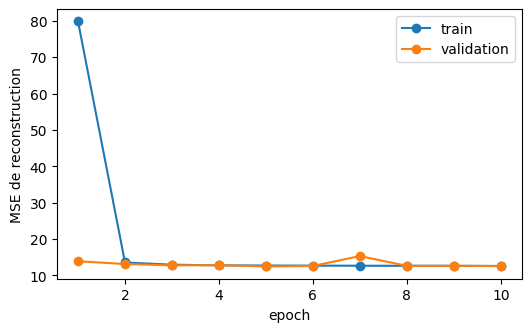

In [7]:
epochs = range(1, EPOCHS + 1)
plt.figure(figsize=(6, 3.5))
plt.plot(epochs, history["train"], "o-", label="train")
plt.plot(epochs, history["validation"], "o-", label="validation")
plt.xlabel("epoch")
plt.ylabel("MSE de reconstruction")
plt.legend()
plt.show()

## 5. Test : AUC et pAUC

Score d'un son = erreur de reconstruction moyenne sur ses 309 vecteurs (comme le papier). On mesure, pour chaque
machine, l'**AUC** et la **pAUC** (AUC limitée aux faux positifs ≤ 10 %), puis leur moyenne : les métriques du
challenge.

In [8]:
@torch.no_grad()
def sound_scores(ds):
    """Score de chaque son du dataset : moyenne de l'erreur de ses vecteurs."""
    model.eval()
    errors = torch.cat([((model(x.to(DEVICE), ids.to(DEVICE)) - x.to(DEVICE)) ** 2).mean(dim=1).cpu()
                        for x, ids, _ in loader(ds, batch=4096)])
    return (torch.bincount(ds.sounds, errors) / torch.bincount(ds.sounds)).numpy()


rows = []
for folder, anomaly in [("test/normal", False), ("test/anomalie", True)]:
    ds = PumpVectors(folder)
    for path, s in zip(ds.files, sound_scores(ds)):
        rows.append({"name": path.stem, "machine": f"id_{machine_id(path):02d}", "anomaly": anomaly, "score": s})
test = pd.DataFrame(rows)

BASELINE = {"id_00": (67.15, 56.74), "id_02": (61.53, 58.10), "id_04": (88.33, 67.10), "id_06": (74.55, 58.02)}
results = pd.DataFrame({
    m: {"AUC": 100 * roc_auc_score(g.anomaly, g.score), "pAUC": 100 * roc_auc_score(g.anomaly, g.score, max_fpr=0.1),
        "AUC papier": BASELINE[m][0], "pAUC papier": BASELINE[m][1]}
    for m, g in test.groupby("machine")}).T
results.loc["moyenne"] = results.mean()
results.round(2)

,AUC,pAUC,AUC papier,pAUC papier
id_00,74.15,58.59,67.15,56.74
id_02,63.92,63.54,61.53,58.10
id_04,94.70,77.79,88.33,67.10
id_06,71.29,59.18,74.55,58.02
moyenne,76.02,64.78,72.89,59.99


## 6. Matrice de confusion

Pour décider « normal » ou « anomalie », il faut un seuil : on prend le quantile 95 % des scores des sons de
**validation** (normaux), soit environ 5 % de fausses alertes attendues. Le seuil est commun aux 4 machines.

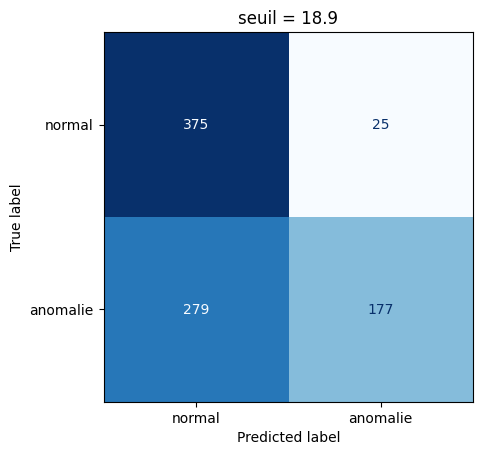

anomalies détectées : 39%, fausses alertes : 6%


In [9]:
threshold = np.quantile(sound_scores(val_ds), 0.95)
test["predicted"] = test.score > threshold

cm = confusion_matrix(test.anomaly, test.predicted)
ConfusionMatrixDisplay(cm, display_labels=["normal", "anomalie"]).plot(cmap="Blues", colorbar=False)
plt.title(f"seuil = {threshold:.1f}")
plt.show()
print(f"anomalies détectées : {test[test.anomaly].predicted.mean():.0%}, "
      f"fausses alertes : {test[~test.anomaly].predicted.mean():.0%}")

## 7. Erreurs restantes

Quelques **faux positifs** (sons normaux jugés anormaux, les plus hauts scores) et **faux négatifs** (anomalies
manquées, les plus bas scores) : log-mel, reconstruction par le modèle et carte d'erreur, avec le son à écouter.

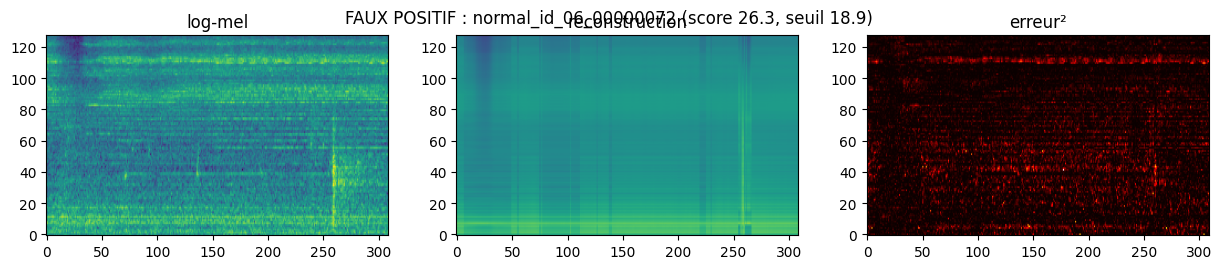

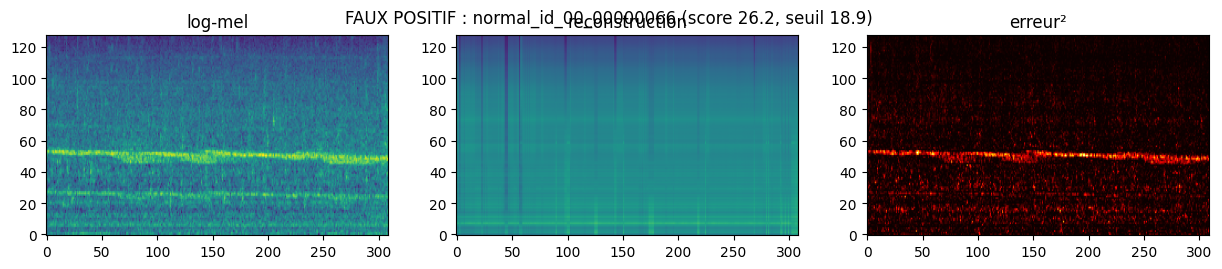

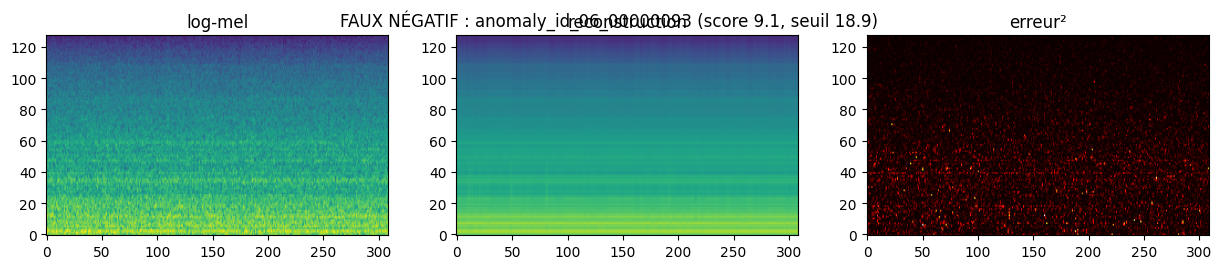

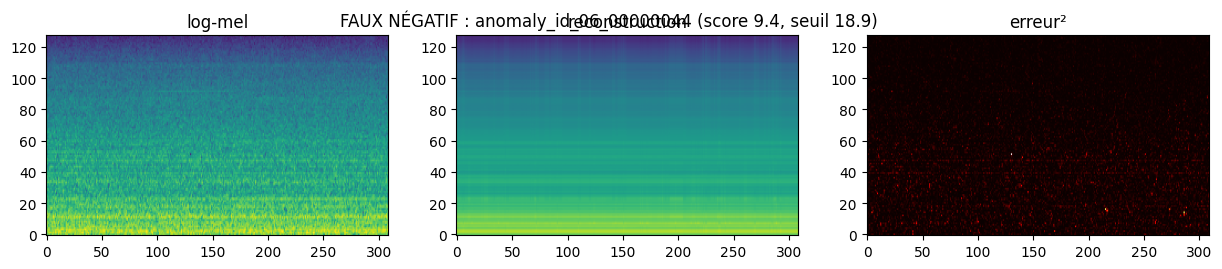

In [10]:
false_pos = test[~test.anomaly & test.predicted].nlargest(2, "score")
false_neg = test[test.anomaly & ~test.predicted].nsmallest(2, "score")

model.eval()
for kind, rows in [("FAUX POSITIF", false_pos), ("FAUX NÉGATIF", false_neg)]:
    for r in rows.itertuples():
        mel = np.load(DATA / ("test/anomalie" if r.anomaly else "test/normal") / f"{r.name}.npy")
        x = to_vectors(mel).to(DEVICE)
        with torch.no_grad():
            rec = model(x, torch.full((len(x),), machine_id(Path(r.name)), device=DEVICE))
        rec = rec[:, :128].T.cpu().numpy()  # première trame de chaque vecteur -> (128, 309)
        orig = mel[:, : rec.shape[1]]
        fig, axes = plt.subplots(1, 3, figsize=(15, 2.6))
        axes[0].imshow(orig, origin="lower", aspect="auto")
        axes[1].imshow(rec, origin="lower", aspect="auto", vmin=orig.min(), vmax=orig.max())
        axes[2].imshow((orig - rec) ** 2, origin="lower", aspect="auto", cmap="hot")
        for ax, title in zip(axes, ["log-mel", "reconstruction", "erreur²"]):
            ax.set_title(title)
        fig.suptitle(f"{kind} : {r.name} (score {r.score:.1f}, seuil {threshold:.1f})")
        plt.show()
        display(Audio(str(WAV / f"{r.name}.wav")))